# Declare a letter-copy variable

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/AdaptiveMotorControlLab/psi/blob/main/notebooks/02-your-own-variable.ipynb)

Generate prompts in Python, check their answer mass and compare candidate layers.

In [1]:
%pip install -q "psi[notebooks] @ git+https://github.com/AdaptiveMotorControlLab/psi"

Choose the model and budget in this cell. Set `SMOKE = True` for a small CPU run.

In [2]:
# Edit these settings directly. SMOKE gives a small CPU check.
SMOKE = False
MODEL_ID = "Qwen/Qwen2.5-0.5B"
EPOCHS = 8
BATCH_SIZE = 4
MAX_LENGTH = 64


In [3]:
%matplotlib inline

import logging
import tempfile
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display

import psi

# These settings are derived from the configuration cell above.
DEVICE = "cpu"
if not SMOKE and torch.cuda.is_available():
    DEVICE = "cuda"
DTYPE = "float32" if DEVICE == "cpu" else "float16"
EPOCHS = 1 if SMOKE else EPOCHS
BATCH_SIZE = 2 if SMOKE else BATCH_SIZE
CACHE = tempfile.mkdtemp(prefix="psi-demo-")
START = time.perf_counter()

torch.set_num_threads(4)
logging.getLogger("lightning.pytorch").setLevel(logging.ERROR)
warnings.formatwarning = (
    lambda message, category, *args, **kwargs: f"{category.__name__}: {message}\n"
)

# Colours and axis treatment follow the paper's figures.
PSI_COLOUR = "#A03BB8"
SECONDARY = "#1E8158"
REFERENCE = "#7593C6"
NO_EDIT = "#BFBFBC"
INK = "#0b0b0b"
INK_SOFT = "#4a4a47"

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 11,
    "axes.labelsize": 11,
    "axes.titlesize": 12,
    "axes.edgecolor": INK,
    "axes.labelcolor": INK,
    "axes.linewidth": 0.8,
    "xtick.color": INK_SOFT,
    "ytick.color": INK_SOFT,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "legend.frameon": False,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "figure.dpi": 120,
    "savefig.dpi": 160,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

Each prompt gives input/output examples and asks for another output letter. Shared `Values` define the answer itself as the variable. The generator supplies no labels and no counterfactual pairs.

In [4]:
prefixes = [
    "",
    "Example:\n",
    "Copy the input.\n",
    "Follow the examples.\n",
    "Task:\n",
    "Repeat the letter.\n",
    "A copying task.\n",
    "Continue the pattern.\n",
]
texts = [
    prefix + (f"Input: {first}\nOutput: {first}\n" * count) + f"Input: {last}\nOutput:"
    for prefix in (prefixes[:2] if SMOKE else prefixes)
    for count in range(1, 3 if SMOKE else 5)
    for first in ["A", "B"]
    for last in ["A", "B"]
]

prompts = psi.Prompts(texts, seed=11)
program = psi.Program(psi.Values([" A", " B"]), rule="copy")
subject = psi.PSI(
    MODEL_ID,
    layer=15,
    device=DEVICE,
    dtype=DTYPE,
    batch_size=BATCH_SIZE,
    max_length=MAX_LENGTH,
    cache_dir=CACHE,
    progress=False,
)

check = program.check(subject, prompts)
print(check)

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

mean_answer_mass: 0.9105874300003052
lowest_answer_mass: 0.7514493465423584
argmax_counts: (64, 64)
gold_agreement: None
leading_space_mass: 0.9105874300003052
warnings: ()


Compare short fits on validation pairs. The highest validation agreement selects a layer; ties choose the later layer, which leaves fewer downstream layers to differentiate during training. Test is evaluated after this selection.

In [5]:
scan = psi.scan_layers(
    subject.subject.model,
    prompts,
    program,
    tokenizer=subject.tokenizer,
    layers=[7, 15, 23],
    epochs=1 if SMOKE else 2,
    rank=16,
    batch_size=BATCH_SIZE,
    max_length=MAX_LENGTH,
    device=DEVICE,
    dtype=DTYPE,
    cache_dir=CACHE,
    progress=False,
)

selection = scan.sort_values(["model_agreement", "layer"], ascending=[False, False])
layer = int(selection.iloc[0]["layer"])
display(scan)

model = psi.PSI(
    subject.subject.model,
    tokenizer=subject.tokenizer,
    layer=layer,
    rank=16,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    max_length=MAX_LENGTH,
    device=DEVICE,
    dtype=DTYPE,
    cache_dir=CACHE,
    progress=False,
)
model.fit(prompts, program)

report = model.score(prompts)
display(report.to_frame())

GPU available: True (cuda), used: True


TPU available: False, using: 0 TPU cores


💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


You are using a CUDA device ('NVIDIA RTX A4000') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision


LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [2]


/opt/venv/lib/python3.12/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/opt/venv/lib/python3.12/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=19` in the `DataLoader` to improve performance.
/opt/venv/lib/python3.12/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=19` in the `DataLoader` to improve performance.


... (15 outputs left out)

LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [2]


/opt/venv/lib/python3.12/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/opt/venv/lib/python3.12/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=19` in the `DataLoader` to improve performance.
/opt/venv/lib/python3.12/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=19` in the `DataLoader` to improve performance.


`Trainer.fit` stopped: `max_epochs=8` reached.


,interchange_agreement,no_edit_baseline,mean_answer_mass,prompts,pairs,steering_success,steering_no_edit,model_agreement,no_edit_model_agreement,decision_rule
0,1.0,0.5,0.930102,12,12,None,None,1.0,0.5,declared-answer argmax


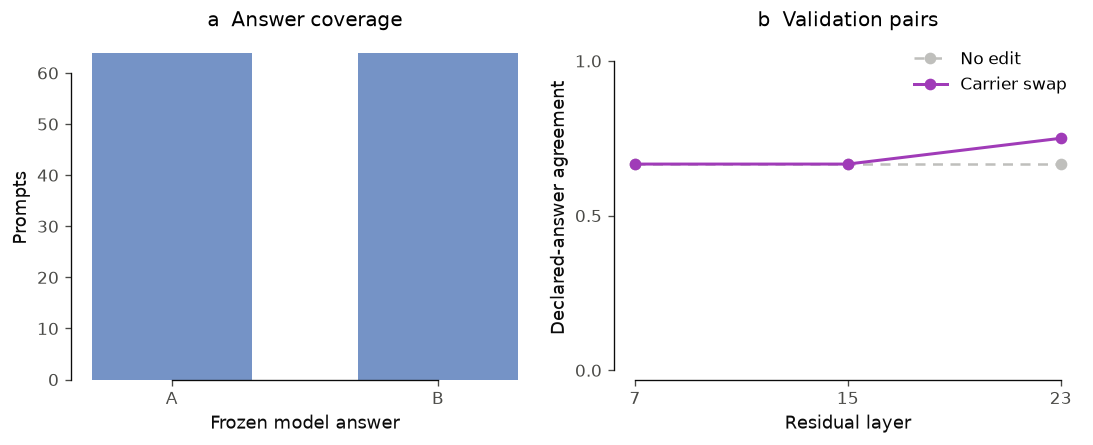

In [6]:
fig, (counts, agreement) = plt.subplots(1, 2, figsize=(9, 3.6), layout="constrained")

answers = list(program.answers.values)
counts.bar(np.arange(len(answers)), check.argmax_counts, color=REFERENCE, width=0.6)
counts.set_xticks(np.arange(len(answers)), [answer.strip() for answer in answers])
counts.set(xlabel="Frozen model answer", ylabel="Prompts", title="a  Answer coverage")
counts.spines[["top", "right"]].set_visible(False)
counts.spines["bottom"].set_bounds(0, len(answers) - 1)
count_ticks = counts.get_yticks()
count_ticks = count_ticks[(count_ticks >= 0) & (count_ticks <= counts.get_ylim()[1])]
counts.set_yticks(count_ticks)
counts.spines["left"].set_bounds(count_ticks[0], count_ticks[-1])

agreement.plot(scan.layer, scan.no_edit_model_agreement, color=NO_EDIT, marker="o", linestyle=(0, (4, 3)), label="No edit")
agreement.plot(scan.layer, scan.model_agreement, color=PSI_COLOUR, marker="o", linewidth=1.8, label="Carrier swap")
agreement.set_xticks(scan.layer)
agreement.set_yticks([0, 0.5, 1])
agreement.set(xlabel="Residual layer", ylabel="Declared-answer agreement", ylim=(-0.03, 1.08), title="b  Validation pairs")
agreement.spines[["top", "right"]].set_visible(False)
agreement.spines["bottom"].set_bounds(scan.layer.min(), scan.layer.max())
agreement.spines["left"].set_bounds(0, 1)
agreement.legend(loc="best")

plt.show()

This run record reports the model, hardware, elapsed time and the held-out scores measured above.

In [7]:
run_summary = {
    "model": MODEL_ID,
    "device": DEVICE,
    "gpu": torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU",
    "runtime_seconds": time.perf_counter() - START,
    "smoke": SMOKE,
    "card": {
        "metric": "Declared-answer agreement",
        "rows": [
            *({"label": f"Layer {int(row.layer)}, validation", "edit": float(row.model_agreement), "baseline": float(row.no_edit_model_agreement)} for row in scan.itertuples()),
            {"label": f"Layer {layer}, test", "edit": float(report.model_agreement), "baseline": float(report.no_edit_model_agreement)},
        ],
        "pairs": int(report.pairs),
    },
}
display({"application/json": run_summary}, raw=True)